# MSE-Bilanz der Luftmasse über Neu-Delhi am 25.05.2015

## Fragestellung

Inwieweit lässt sich die Änderung der mittleren feuchten statischen Energie (MSE) entlang rückwärts berechneter FLEXPART-Trajektoerien durch Oberflächenwärmeflüsse und Strahlung erklären?

## Testfall

- Rezeptor: Neu-Delhi
- Release Zeitpunkt: 25.05.2015 12:00 UTC
- Rückwärtslauf bis 15.05.2015 12:00 UTC
- OUTGRID: 0.5°, 42 Höhenschichten

## Ansatz

MSE-Änderung = Oberflächenbeitrag + Strahlungsbeitrag + Residuals

Alle Beiträge werden als spezifische Energie in J/kg ausgewertet.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import eccodes

In [3]:
run_dir = Path("/jetfs/scratch/gbrack/flexpart_output/new_delhi_10d_0.5deg")
grid_file = run_dir / "grid_time_20150525120000.nc"
surface_file = Path("/jetfs/scratch/gbrack/MSC/ERA_SHF_LHF_Pr.nc")
radiation_dir = Path("/jetfs/scratch/gbrack/MSC/rad_data/2015/05")
met_dir = Path("/jetfs/shared-data/ECMWF/ERA5_glob_0.5deg_1h")

assert grid_file.is_file(), grid_file
assert surface_file.is_file(), surface_file
assert radiation_dir.is_dir(), radiation_dir
assert met_dir.is_dir(), met_dir

print("All Data available.")

All Data available.


## 1. Änderung der MSE

Für jedes Partikel berechnen wir die spezifische MSE.

$$
MSE_p = h_p = c_p T_p(t) + L_v q_p(t) + g \left [z_{\mathrm{AGL},p}(t) + z_{\mathrm{ORO}, p}(t) \right]
$$

Dabei:

- $c_p$: spezifische Wärmekapazität von Luft
- $T_p$: Temperatur des Partikels in K
- $L_v$: spezifische Verdampfungswärme
- $q_p$: spezifische Feuchte
- $z_{\mathrm{AGL},p}$: Partikelhöhe über Grund in m
- $z_{\mathrm{ORO}, p}$: Orographie

Für dieselben Partikel an den Endpunkten ergibt sich:

$$
\Delta \overline{MSE} = \Delta \overline{h} = \frac{1}{N_{\mathrm{gültig}}} \sum_{p \in \mathcal{V}} \left[ h_p(t_{\mathrm{Ende}}) - h_p(t_{\mathrm{Anfang}})
\right]
$$

In [4]:
grid = xr.open_dataset(grid_file)
particle_files = run_dir.glob("partoutput_*.nc")

particles = xr.open_mfdataset(particle_files, combine="by_coords")

print("earliest particle time stamp:", particles.time.min().values)
print("latest particle time stamp:", particles.time.max().values)
print("number of particles:", particles.sizes["particle"])

earliest particle time stamp: 2015-05-15T12:00:00.000000000
latest particle time stamp: 2015-05-25T11:00:00.000000000
number of particles: 20000


In [5]:
cp = 1004.6 # J / (kg K)
Lv = 2501000 # J / kg
g = 9.81 # m / s^2

def calculate_mse(state):
    longitude = ((state.lon + 180) % 360) - 180

    ground_height = grid.ORO.interp(
        longitude=longitude,
        latitude=state.lat
    )

    temperature_energy = cp * state.T.astype("float64")
    latent_energy = Lv * state.sh.astype("float64")
    potential_energy = g * (state.z.astype("float64") + ground_height)

    return temperature_energy + latent_energy + potential_energy

In [6]:
initial_state = particles.sel(time=particles.time.min().values)
final_state = particles.sel(time=particles.time.max().values)

mse_initial = calculate_mse(initial_state)
mse_final = calculate_mse(final_state)

In [7]:
valid_particles = np.isfinite(mse_initial) & np.isfinite(mse_final)

n_valid = valid_particles.sum().compute().item()
n_total = particles.sizes["particle"]

print(f"valid particles: {n_valid} of {n_total}")
print(f"excluded: {n_total - n_valid}")

valid particles: 19827 of 20000
excluded: 173


In [8]:
mean_mse_initial = mse_initial.where(valid_particles).mean(dim="particle", skipna=True).compute().item()
mean_mse_final = mse_final.where(valid_particles).mean(dim="particle", skipna=True).compute().item()
delta_mse = (mse_final - mse_initial).where(valid_particles).mean(dim="particle", skipna=True).compute().item()

In [9]:
print("Init: ", initial_state.time.values)
print("End: ", initial_state.time.values)

print(f"mean mse init: {mean_mse_initial / 1000:.3f} kJ/kg")
print(f"mean mse end:  {mean_mse_final / 1000:.3f} kJ/kg")
print(f"mse change:    {delta_mse / 1000:.3f} kJ/kg")

Init:  2015-05-15T12:00:00.000000000
End:  2015-05-15T12:00:00.000000000
mean mse init: 322.374 kJ/kg
mean mse end:  330.496 kJ/kg
mse change:    8.122 kJ/kg


In [10]:
np.testing.assert_allclose(delta_mse, mean_mse_final - mean_mse_initial, atol=1)

### Einordnung

Die berechnete Änderung beschreibt die Nettoänderung zwischen den verfügbaren Partikel-Endpunkten. Partikel mit fehlenden Werten werden an beiden Endpunkten gemeinsam ausgeschlossen. Die spätere MSE Bilanz bezieht sich auf ALLE Partikel, das ist (jetzt noch) etwas inkonsistent, bei 173/20000 fehlenden Partikeln aber zu vernachlässigen.

### Beiträge zur MSE Änderung

In [11]:
def mean_particle_change(variable):
    difference = (final_state[variable].astype("float64") - initial_state[variable].astype("float64"))
    return difference.where(valid_particles).mean(dim="particle", skipna=True).compute().item()

delta_temperature = cp * mean_particle_change("T")
delta_humidity = Lv * mean_particle_change("sh")
delta_height_agl = g * mean_particle_change("z")

def ground_at_particles(state):
    return grid.ORO.interp(
        longitude=((state.lon + 180) % 360) - 180,
        latitude=state.lat
    )

delta_ground = g * (ground_at_particles(final_state) - ground_at_particles(initial_state)).where(valid_particles).mean(dim="particle", skipna=True).compute().item()

mse_contributions = pd.Series({
    "temperature": delta_temperature,
    "humidity": delta_humidity,
    "height above ground level": delta_height_agl,
    "ground level": delta_ground
}, name="Change [J/kg]")

display((mse_contributions))

temperature                  50071.359612
humidity                      7662.288469
height above ground level   -49546.715591
ground level                   -64.593173
Name: Change [J/kg], dtype: float64

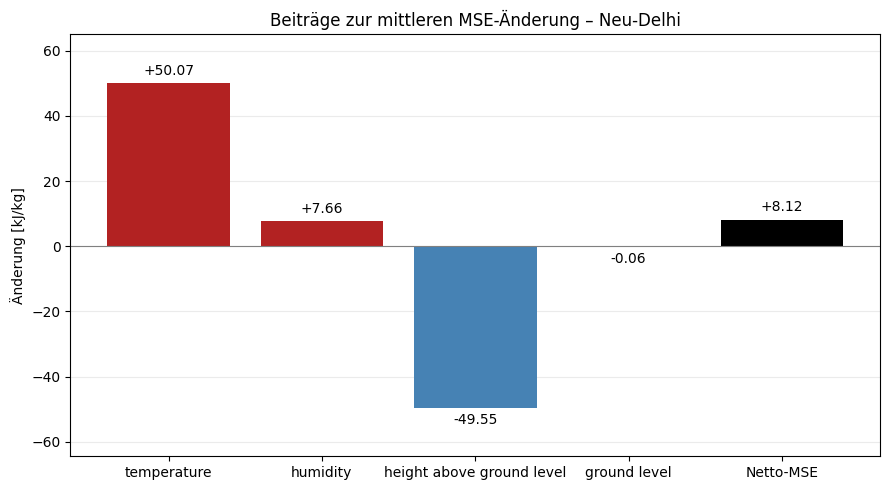

In [12]:
plot_values = mse_contributions / 1000
plot_values.loc["Netto-MSE"] = delta_mse / 1000

colors = [
    "firebrick" if value >= 0 else "steelblue"
    for value in plot_values
]
colors[-1] = "black"

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(plot_values.index, plot_values.values, color=colors)

ax.axhline(0, color="gray", linewidth=0.8)
ax.set_ylabel("Änderung [kJ/kg]")
ax.set_title("Beiträge zur mittleren MSE-Änderung – Neu-Delhi")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

ax.bar_label(bars, fmt="%+.2f", padding=4)
ax.margins(y=0.15)

plt.tight_layout()
plt.show()

## 2. Beitrag der Oberflächenwärmeflüsse

Wir berücksichtigen den sensiblen und latenten Wärmefluss zwischen Surface und den untersten 100m in FLEXPART. Die FLEXPART-Sensitivitäten dieser Schicht werden mit einer über diese Scheicht verteilten Energiequelle gewichtet. Für den Vergleich verwenden wir nur die Stundenintervalle zwischen den zuvor gewählten Partikel-Endpunkten.

In [13]:
start_time = initial_state.time.values
end_time = final_state.time.values
grid_times = grid.time
use_interval = (grid_times >= start_time) & (grid_times + np.timedelta64(1, "h") <= end_time)
grid_budget = grid.sel(time=grid_times[use_interval])

duration_hours = float((end_time - start_time) / np.timedelta64(1, "h"))

n_intervals = grid_budget.sizes["time"]

print("particle init: ", start_time)
print("particle end:  ", end_time)
print("duration:      ", duration_hours, "h")
print("grid intervals:", n_intervals)

assert n_intervals == duration_hours

particle init:  2015-05-15T12:00:00.000000000
particle end:   2015-05-25T11:00:00.000000000
duration:       239.0 h
grid intervals: 239


In [14]:
surface = xr.open_dataset(surface_file).rename({"valid_time": "time"})
surface_aligned = surface.reindex_like(grid_budget)

sensitivity_surface = grid_budget["spec001_mr"].sel(height=100).squeeze()

dt = 3600
layer_height = 100

surface_sensible = (sensitivity_surface * (-surface_aligned.sshf) / (dt * layer_height))
surface_latent = (sensitivity_surface * (-surface_aligned.slhf) / (dt * layer_height))

In [17]:
total_sensible = surface_sensible.sum(skipna=False).compute().item()
total_latent = surface_latent.sum(skipna=False).compute().item()

total_surface = total_sensible + total_latent

print(f"sensible heat added: {total_sensible / 1000:.3f} kJ/kg")
print(f"latent heat added: {total_latent / 1000:.3f} kJ/kg")

print(f"surface total: {total_surface / 1000:.3f} kJ/kg")

sensible heat added: 7.866 kJ/kg
latent heat added: 5.315 kJ/kg
surface total: 13.181 kJ/kg


In [18]:
surface_times = surface.reindex_like(grid)

full_contribution = (
    grid["spec001_mr"].sel(height=100).squeeze()
    * (-surface_times["sshf"] - surface_times["slhf"])
    / (3600 * 100)
)

full_total = full_contribution.sum(skipna=False).compute().item()

print("full output:", full_total / 1000, "kJ/kg")
print("shared:", total_surface / 1000, "kJ/kg")
print("excluded:", (full_total - total_surface) / 1000, "kJ/kg")

full output: 15.245351321166224 kJ/kg
shared: 13.181194526620475 kJ/kg
excluded: 2.0641567945457484 kJ/kg


### Zeitliche Zuordnung

Der FLEXPART-Zeitstempel bezeichnet den Anfang des betrachteten
Stundenintervalls. Die stündliche ERA5-Flussakkumulation ist am
Ende dieses Intervalls gespeichert.

Daher wird dem FLEXPART-Zeitpunkt $t$ der ERA5-Wert bei
$t + 1\,\mathrm{h}$ zugeordnet.

In [19]:
surface_shifted = surface.assign_coords(
    time=surface.time - np.timedelta64(1, "h")
)

surface_aligned = surface_shifted.sel(
    time=grid_budget.time,
    latitude=grid_budget.latitude,
    longitude=grid_budget.longitude,
)

## 3. Beitrag der Strahlung

ERA5 liefert Temperaturtendenzen durch SW und LW Strahlung auf den 137 Modelllevels, jeweils in K/s. Wir rechnen sie in eine volumetrische Energiequelle um:

$$
Q_{\mathrm{rad}} = \rho\,c_p \left( \dot{T}_{\mathrm{SW}} + \dot{T}_{\mathrm{LW}} \right)
$$

$ Q_{\mathrm{rad}} $ hat die Einheit J / m^3 / s

Nach der vertikalen Mittelung auf die FLEXPART-Ausgabeschichten berechnen wir den Beitrag zur spezifischen Energie am Rezeptor:

$$
\Delta MSE_{\mathrm{rad}} = \Delta h_{\mathrm{rad}} = \sum_{t, k, x, y} S_{t, k, x, y}\,\overline{Q}_{\mathrm{rad},t, k, x, y}
$$

Die Sensitivität $S$ hat die Einheit s m^3 / kg. Das Ergebnis liegt daher in J / kg vor. Eine zusätzliche Multiplikation mit der Intervalldauer ist nicht notwendig. Die Vorzeichen der Strahlungstendenzen bleiben erhalten - negativ cooling, positiv warming

In [20]:
radiation_files = radiation_dir.glob("TMTTRAD_*.nc")

radiation = xr.open_mfdataset(radiation_files, combine="by_coords").sortby("valid_time").sortby("model_level")

In [21]:
radiation_times = (
    grid_budget.time.values + np.timedelta64(1, "h")
)

radiation_selected = radiation.sel(
    valid_time=radiation_times
)

In [22]:
print("End of first radiation interval:", radiation_selected.valid_time.values[0])
print("End of last radiation inverval: ", radiation_selected.valid_time.values[-1])
print("Number:", radiation_selected.sizes["valid_time"])

End of first radiation interval: 2015-05-25T11:00:00.000000000
End of last radiation inverval:  2015-05-15T13:00:00.000000000
Number: 239


### Meteorologische Daten für die vertikale Zuordnung

Die ERA5-Modelllevel besitzen keine festen Höhen über Grund. Wir berechnen ihre Höhe und die Luftdichte für jeden Ort und Zeitpunkt aus den vorhandenen meteorologischen Eingabedaten.

Dafür verwenden wir:
- Temperatur $T$ und spezifische Feuchte $q$ auf allen 137 Modellleveln
- Oberflächendruck
- Oberflächengeopotential
- Hybridkoeffizienten der Modelllevel

Die Meteorologie am Ende des jeweiligen Strahlungsintervalls dienst als Näherung für die Bedingungen während dieser Stunde. 

In [23]:
# Timestamp auf pfad ummodeln (2015-05-15 13:00 wird zu 2015/05/EA2015051513)

def met_file_for(time):
    timestamp = pd.Timestamp(time)
    return met_dir / timestamp.strftime("%Y/%m/EA%Y%m%d%H")

In [24]:
def select_output_grid(dataset):
    longitude = ((dataset.longitude + 180) % 360) - 180
    dataset = dataset.assign_coords(
        longitude=longitude
    ).sortby("longitude")
    return dataset.sel(latitude=grid_budget.latitude, longitude=grid_budget.longitude)

In [25]:
def read_meteorology(time):
    pieces = []

    for parameter in [130, 133, 134, 129]:
        dataset = xr.open_dataset(
            met_file_for(time),
            engine="cfgrib",
            backend_kwargs={
                "filter_by_keys": {
                    "paramId": parameter
                },
                "indexpath": "",
            }
        )

        try:
            selected = select_output_grid(dataset)

            selected = selected.drop_vars(
                "surface",
                errors="ignore"
            )

            pieces.append(selected.load())

        finally:
            dataset.close()

    return xr.merge(
        pieces,
        join="exact",
    ).sortby("hybrid")

In [26]:
test_time = radiation_selected.valid_time.min().values

met_test = read_meteorology(test_time)

display(met_test)

<xarray.Dataset> Size: 107MB
Dimensions:     (hybrid: 137, latitude: 230, longitude: 420)
Coordinates:
    time        datetime64[ns] 8B 2015-05-15T13:00:00
    step        timedelta64[ns] 8B 00:00:00
  * hybrid      (hybrid) float64 1kB 1.0 2.0 3.0 4.0 ... 134.0 135.0 136.0 137.0
  * latitude    (latitude) float64 2kB -30.0 -29.5 -29.0 ... 83.5 84.0 84.5
    valid_time  datetime64[ns] 8B 2015-05-15T13:00:00
  * longitude   (longitude) float64 3kB -90.0 -89.5 -89.0 ... 118.5 119.0 119.5
    number      int64 8B 0
Data variables:
    t           (hybrid, latitude, longitude) float32 53MB 201.5 201.6 ... 264.2
    q           (hybrid, latitude, longitude) float32 53MB 1.701e-06 ... 0.00...
    sp          (latitude, longitude) float32 386kB 1.02e+05 ... 9.973e+04
    z           (latitude, longitude) float32 386kB 5.131 -4.455 ... 2.17 4.01
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-29T05:55 GRIB to CDM+CF via cfgrib-0.9.1...

### Druck auf den ERA5 Modellleveln

Die 137 Modellschichten werden von 138 Schichtgrenzen eingeschlossen. Der Druck an jeder grenze ergibt sich folgendermaßen:

$$ 
p_{k+\frac{1}{2}} = a_{k+\frac{1}{2}} + b_{k+\frac{1}{2}}\,p_s
$$

Dabei ist $p_s$ der örtliche Oberflächendruck. Der Koeffizient $a$ hat die Einheit $Pa$, $b$ ist dimensionslos, weil er mit dem Oberflächendruck multipliziert wird. 

Die Druck- und Höhenberechnung folgt der
[ECMWF-Anleitung für ERA5-Modelllevel](https://confluence.ecmwf.int/pages/viewpage.action?pageId=158636068).

In [27]:
def read_hybrid_coefficients(filename):
    with open(filename, "rb") as file:
        while True:
            message = eccodes.codes_grib_new_from_file(file)

            if message is None:
                raise ValueError("Kein Temperaturfeld gefunden.")

            try:
                parameter = eccodes.codes_get(
                    message, "paramId"
                )

                if parameter == 130:
                    coefficients = np.asarray(
                        eccodes.codes_get_array(message, "pv"),
                        dtype="float"
                    )
                    break
            
            finally:
                eccodes.codes_release(message)

    assert coefficients.size == 276

    a_half = coefficients[:138]
    b_half = coefficients[138:]

    return a_half, b_half

In [28]:
a_half, b_half = read_hybrid_coefficients(met_file_for(test_time))

print("a-coefficients:", a_half.shape)
print("b-coefficients:", b_half.shape)

a-coefficients: (138,)
b-coefficients: (138,)


### Druck und Luftdichte

Der Druck auf einem vollen Modelllevel wird aus den angrenzenden
Schichtgrenzen berechnet:

$$
p_k = \frac{p_{k-\frac{1}{2}} + p_{k+\frac{1}{2}}}{2}
$$

Die virtuelle Temperatur berücksichtigt den Einfluss der Luftfeuchte:

$$
T_{v,k} = T_k \left(1 + 0.609133\,q_k\right)
$$

Damit ergibt sich näherungsweise die Luftdichte:

$$
\rho_k = \frac{p_k}{R_d T_{v,k}}
$$

Dabei ist $R_d = 287.06\,\mathrm{J\,kg^{-1}\,K^{-1}}$.

In [29]:
def geometric_altitude(geopotential):
    geopotential_height = geopotential / g0

    return (earth_radius * geopotential_height) / (earth_radius - geopotential_height)

Die hydrostatische Integration hab ich zum Teil aus dem ECMWF Beispielcode, den ich oben verlinkt hab. Das Einlesen und die Array-Verarbeitung sind angepasst. Zusätzlich werden Schichtgrenzen gespeichert.

In [30]:
Rd = 287.06
g0 = 9.80665
earth_radius = 6371000.0

def calculate_geometry(met, a_half, b_half):
    met = met.sortby("hybrid")

    temperature = met["t"].transpose(
        "hybrid", "latitude", "longitude"
    ).values.astype("float64")

    humidity = met["q"].transpose(
        "hybrid", "latitude", "longitude"
    ).values.astype("float64")

    surface_pressure = met["sp"].transpose(
        "latitude", "longitude"
    ).values.astype("float64")

    surface_geopotential = met["z"].transpose(
        "latitude", "longitude"
    ).values.astype("float64")

    virtual_temperature = temperature * (
        1.0 + 0.609133 * humidity
    )

    pressure_half = (
        a_half[:, None, None]
        + b_half[:, None, None] * surface_pressure
    )

    pressure_full = (
        pressure_half[:-1] + pressure_half[1:]
    ) / 2.0

    density = pressure_full / (
        Rd * virtual_temperature
    )

    geopotential_full = np.empty_like(temperature)
    geopotential_half = np.empty_like(pressure_half)

    geopotential_half[137] = 0.0

    for level in range(137, 0, -1):
        p_lower = pressure_half[level]
        p_upper = pressure_half[level - 1]

        rt = Rd * virtual_temperature[level -1]

        if level == 1:
            dlog_p = np.log(p_lower / 0.1)
            alpha = np.log(2.0)
        else:
            dlog_p = np.log(p_lower / p_upper)

            alpha = 1.0 - (p_upper / (p_lower - p_upper) * dlog_p)

        geopotential_full[level - 1] = (geopotential_half[level] + rt * alpha)
        geopotential_half[level - 1] = (geopotential_half[level] + rt * dlog_p)

    geopotential_half[0] = np.inf

    ground_altitude = geometric_altitude(surface_geopotential)
    height_full = geometric_altitude(surface_geopotential + geopotential_full) - ground_altitude
    
    height_half = np.empty_like(geopotential_half)

    height_half[1:] = geometric_altitude(surface_geopotential + geopotential_half[1:]) - ground_altitude
    height_half[0] = np.inf

    return height_full, height_half, density

In [31]:
height_test, boundaries_test, density_test = calculate_geometry(met_test, a_half, b_half)

print("model level heights:", height_test.shape)
print("boundaries:         ", boundaries_test.shape)
print("desnity:            ", density_test.shape)

model level heights: (137, 230, 420)
boundaries:          (138, 230, 420)
desnity:             (137, 230, 420)


In [32]:
assert np.all(np.isfinite(height_test))
assert np.all(np.isfinite(density_test))
assert np.all(density_test > 0)

assert np.all(height_test > boundaries_test[1:])
assert np.all(height_test < boundaries_test[:-1])

np.testing.assert_allclose(boundaries_test[-1], 0.0, atol=1e-8)

print("Height and density are consistent")

Height and density are consistent


In [33]:
# Test for New-Delhi

latitude_index = int(np.argmin(abs(met_test.latitude.values - 28.6)))
longitude_index = int(np.argmin(abs(met_test.longitude.values - 77.2)))

test_latitude = met_test.latitude.values[latitude_index]
test_longitude = met_test.longitude.values[longitude_index]

In [34]:
radiation_profile = radiation_selected.sel(
    valid_time=test_time,
    latitude=test_latitude,
    longitude=test_longitude
).sortby("model_level")

np.testing.assert_array_equal(
    radiation_profile.model_level.values,
    met_test.hybrid.values
)

height_profile = height_test[:, latitude_index, longitude_index]

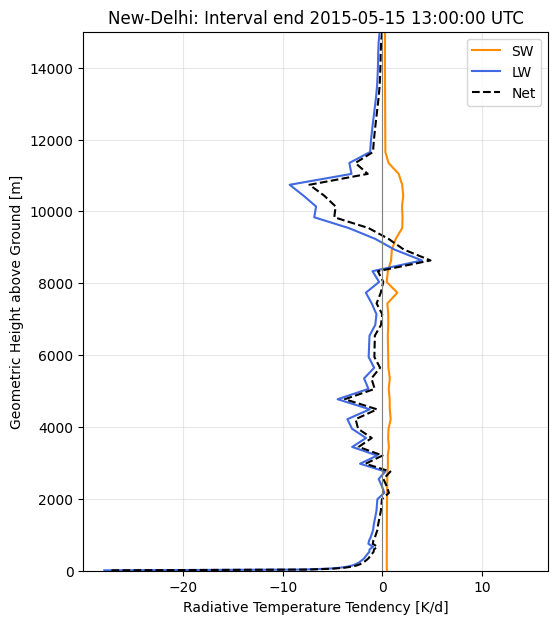

In [35]:
sw_profile = radiation_profile["avg_ttswr"].values * 86400
lw_profile = radiation_profile["avg_ttlwr"].values * 86400

fig, ax = plt.subplots(1, 1, figsize=(6, 7))

ax.plot(sw_profile, height_profile, color="darkorange", label="SW")
ax.plot(lw_profile, height_profile, color="royalblue", label="LW")
ax.plot(sw_profile + lw_profile, height_profile, color="black", linestyle="--", label="Net")

ax.axvline(0, c="gray", lw=0.8)

ax.set_xlabel("Radiative Temperature Tendency [K/d]")
ax.set_ylabel("Geometric Height above Ground [m]")
ax.set_ylim(0, 15000)
ax.set_title(f"New-Delhi: Interval end {pd.Timestamp(test_time)} UTC")

ax.grid(alpha=0.3)
ax.legend()

### Vertikale Mittelung auf die FLEXPART-Schichten

Zuerst wird auf jedem ERA5-Modelllevel die volumetrische Strahlungsquelle berechnet:

$$
Q_k = \rho_k c_p \dot{T}_k
$$

Innerhalb jeder ERA5-Schicht nehmen wir $Q_k$ als konstant an. Das Mittel für eine FLEXPART-Schicht $j$ lautet:

$$
\overline{Q}_j = \frac{1}{\Delta z_j} \sum_k Q_k\,\Delta z_{k,j}
$$

$\Delta z_{k,j}$ ist die vertikale Überlappung zwischen der ERA5-Schicht $k$ und der FLEXPART-Schicht $j$

Diese Mittelung bildet die unbekannte Verteilung der Partikel innerhalb einer Ausgabe schicht zwar nicht genau ab, das macht aber nichts.

In [36]:
def average_to_flexpart_layers(source, boundaries, upper_bounds):
    layer_means = []
    bottom = 0.0

    for top in upper_bounds:
        overlap = np.maximum(
            0.0,
            np.minimum(boundaries[:-1], top) - np.maximum(boundaries[1:], bottom)
        )

        np.testing.assert_allclose(
            overlap.sum(axis=0),
            top - bottom,
            rtol=1e-8,
            atol=1e-6
        )

        layer_mean = (
            source * overlap
        ).sum(axis=0) / (top - bottom)

        layer_means.append(layer_mean)
        bottom = top

    return np.stack(layer_means)

In [37]:
radiation_test = select_output_grid(radiation_selected.sel(valid_time=test_time)).sortby("model_level")

np.testing.assert_array_equal(
    radiation_test.model_level.values,
    met_test.hybrid.values
)

sw_test = radiation_test["avg_ttswr"].transpose(
    "model_level", "latitude", "longitude"
).values

lw_test = radiation_test["avg_ttlwr"].transpose(
    "model_level", "latitude", "longitude"
).values

assert np.all(np.isfinite(sw_test))
assert np.all(np.isfinite(lw_test))

In [38]:
source_sw = cp * density_test * sw_test
source_lw = cp * density_test * lw_test

layer_source_sw = average_to_flexpart_layers(
    source_sw,
    boundaries_test,
    grid_budget.height.values
)

layer_source_lw = average_to_flexpart_layers(
    source_lw,
    boundaries_test,
    grid_budget.height.values
)

### Gewichtung der FLEXPART-Sensitivität

Für jede Gitterzellt und Höhenschicht multiplizieren wir die gemittelte Strahlungsquelle mit der Rückwärtssensitivität:

$$
\Delta h_{\mathrm{rad},t,j,x,y} = S_{t,j,x,y} \, \overline{Q}_{\mathrm{rad},t,j,x,y}
$$

Die Einheiten ergeben:

$$
\frac{\mathrm{s\, m^3}}{\mathrm{kg}} \cdot \frac{\mathrm{J}}{\mathrm{m^3 \, s}} = \frac{\mathrm{J}}{\mathrm{kg}}
$$

Die Summer über alle Gitterzellen und Schichten liefert den Strahlungsbeitrag dieses Stundenintervalls zur Rezeptorbilanz.

In [39]:
interval_start = (np.datetime64(test_time) - np.timedelta64(1, "h"))

sensitivity_test = grid_budget.spec001_mr.sel(time=interval_start)

sensitivity_test = sensitivity_test.isel(nageclass=0, pointspec=0, drop=True).transpose("height", "latitude", "longitude")

In [40]:
dimensions = ("height", "latitude", "longitude")

coordinates = {name: sensitivity_test[name] for name in dimensions}

source_test = xr.Dataset({
    "sw": xr.DataArray(
        layer_source_sw,
        dims=dimensions,
        coords=coordinates
    ),
    "lw": xr.DataArray(
        layer_source_lw,
        dims=dimensions,
        coords=coordinates
    )
})

In [41]:
contribution_test = source_test * sensitivity_test

contribution_test["net"] = (
    contribution_test.sw + contribution_test.lw
)

totals_test = contribution_test.sum(
    dim=dimensions,
    skipna=False
).compute()

In [42]:
print("interval start:", interval_start)
print("interval end:  ", test_time )

for name in ["sw", "lw", "net"]:
    print(f"{name}: {totals_test[name].item():+.2f} J/kg")

interval start: 2015-05-15T12:00:00.000000000
interval end:   2015-05-15T13:00:00.000000000
sw: +83.86 J/kg
lw: -63.14 J/kg
net: +20.72 J/kg


In [43]:
def radiation_contribution_for_hour(interval_end):
    met = read_meteorology(interval_end)

    heights, boundaries, density = calculate_geometry(met, a_half, b_half)

    radiation_hour = select_output_grid(radiation_selected.sel(valid_time=interval_end)).sortby("model_level")

    np.testing.assert_array_equal(
        radiation_hour.model_level.values,
        met.hybrid.values
    )

    sw = radiation_hour.avg_ttswr.transpose("model_level", "latitude", "longitude").values
    lw = radiation_hour.avg_ttlwr.transpose("model_level", "latitude", "longitude").values

    assert np.all(np.isfinite(sw))
    assert np.all(np.isfinite(lw))

    source_sw = average_to_flexpart_layers(
        cp * density * sw,
        boundaries,
        grid_budget.height.values
    )

    source_lw = average_to_flexpart_layers(
        cp * density * lw,
        boundaries,
        grid_budget.height.values,
    )

    interval_start = (np.datetime64(interval_end) - np.timedelta64(1, "h"))

    sensitivity = grid_budget.spec001_mr.sel(time=interval_start).isel(
        nageclass=0,
        pointspec=0,
        drop=True
    ).transpose("height", "latitude", "longitude")

    dimensions = ("height", "latitude", "longitude")

    coordinates = {name: sensitivity[name] for name in dimensions}
    sources = xr.Dataset({
        "sw": xr.DataArray(source_sw, dims=dimensions, coords=coordinates),
        "lw": xr.DataArray(source_lw, dims=dimensions, coords=coordinates)
    })

    contribution = sources * sensitivity

    contribution = sources * sensitivity

    contribution["net"] = (
        contribution.sw + contribution.lw
    )

    for name in contribution.data_vars:
        contribution[name].attrs["units"] = "J kg-1"

    return contribution.expand_dims(
        time=[interval_start]
    )

In [44]:
hour_check = radiation_contribution_for_hour(test_time)

check_totals = hour_check.sum(
    dim=["time", "height", "latitude", "longitude"],
    skipna=False,
).compute()

for name in ["sw", "lw", "net"]:
    np.testing.assert_allclose(
        check_totals[name].item(),
        totals_test[name].item(),
    )

print("reproduced!")

reproduced!


In [45]:
# alle ergebnisse speichern

result_dir = Path("/jetfs/scratch/gbrack/MSC/mse_budget_new_delhi/radiation")

result_dir.mkdir(parents=True, exist_ok=True)

In [46]:
result_files = []

interval_ends = np.sort(
    radiation_selected.valid_time.values
)

for interval_end in interval_ends:
    timestamp = pd.Timestamp(interval_end)

    filename = result_dir / timestamp.strftime("radiation_end_%Y%m%d%H.nc")

    if filename.exists():
        print("Already_existing:", timestamp, flush=True)

    else:
        contribution = radiation_contribution_for_hour(interval_end).compute()
        temporary_file = filename.with_suffix(".nc.part")

        contribution.to_netcdf(
            temporary_file,
            engine="netcdf4",
            encoding={
                name: {
                    "zlib": True,
                    "complevel": 4,
                }
                for name in contribution.data_vars
            }
        )

        temporary_file.replace(filename)

        net_contribution = contribution.net.sum(skipna=False).item()

        print(
            f"Interval end {timestamp}: {net_contribution:+.2f} J/kg", flush=True
        )

    result_files.append(filename)

Already_existing: 2015-05-15 13:00:00
Already_existing: 2015-05-15 14:00:00
Already_existing: 2015-05-15 15:00:00
Already_existing: 2015-05-15 16:00:00
Already_existing: 2015-05-15 17:00:00
Already_existing: 2015-05-15 18:00:00
Already_existing: 2015-05-15 19:00:00
Already_existing: 2015-05-15 20:00:00
Already_existing: 2015-05-15 21:00:00
Already_existing: 2015-05-15 22:00:00
Already_existing: 2015-05-15 23:00:00
Already_existing: 2015-05-16 00:00:00
Already_existing: 2015-05-16 01:00:00
Already_existing: 2015-05-16 02:00:00
Already_existing: 2015-05-16 03:00:00
Already_existing: 2015-05-16 04:00:00
Already_existing: 2015-05-16 05:00:00
Already_existing: 2015-05-16 06:00:00
Already_existing: 2015-05-16 07:00:00
Already_existing: 2015-05-16 08:00:00
Already_existing: 2015-05-16 09:00:00
Already_existing: 2015-05-16 10:00:00
Already_existing: 2015-05-16 11:00:00
Already_existing: 2015-05-16 12:00:00
Already_existing: 2015-05-16 13:00:00
Already_existing: 2015-05-16 14:00:00
Already_exis

In [47]:
radiation_budget = xr.open_mfdataset(
    result_files,
).sortby("time")

In [48]:
np.testing.assert_array_equal(
    radiation_budget.time.values,
    np.sort(grid_budget.time.values)
)

print("All", radiation_budget.sizes["time"], "1-hour-intervals are available.")

All 239 1-hour-intervals are available.


In [49]:
radiation_totals = radiation_budget.sum(
    dim=["time", "height", "latitude", "longitude"],
    skipna=False
).compute()

total_sw = radiation_totals.sw.item()
total_lw = radiation_totals.lw.item()
total_radiation = radiation_totals.net.item()

print(f"Shortwave: {total_sw / 1000:+.3f} kJ/kg")
print(f"Longwave:  {total_lw / 1000:+.3f} kJ/kg")
print(f"Net:       {total_radiation / 1000:+.3f} kJ/kg")

Shortwave: +11.215 kJ/kg
Longwave:  -17.170 kJ/kg
Net:       -5.955 kJ/kg


### Zeitlich integrierter Strahlungsbeitrag

Die Beiträge aller berücksichtigten Stunden, Höhenschichten und horizontalen Gitterzellenw erden aufsummiert.

Kurzwellige und langwellige Beiträge bleiben zuerst noch getrennt:

$$
\Delta h_{\mathrm{rad}} = \Delta h_{\mathrm{SW}} + \Delta h_{\mathrm{LW}}
$$

Die Summe beschreibt einen Beitrag zur spezifischen Energie der betrachteten Luftmasse am Rezeptor (spezifische Energie heißt J/kg).

In [50]:
radiation_budget.nbytes / 1048**2

21189.12785531146

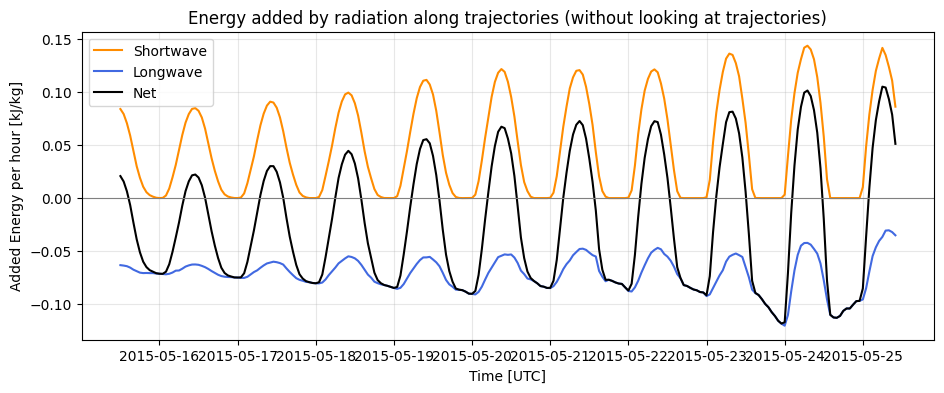

In [51]:
radiation_timeline = radiation_budget.sum(
    dim=["height", "latitude", "longitude"], skipna=False
).compute()

fig, ax = plt.subplots(1, 1, figsize=(11, 4))

plotting_list = [
    ("sw", "Shortwave", "darkorange"),
    ("lw", "Longwave", "royalblue"),
    ("net", "Net", "black")
]

for name, label, color in plotting_list:
    ax.plot(
        radiation_timeline.time,
        radiation_timeline[name] / 1000,
        label=label,
        color=color
    )

ax.axhline(0, c="gray", lw=0.8)
ax.set_xlabel("Time [UTC]")
ax.set_ylabel("Added Energy per hour [kJ/kg]")
ax.set_title("Energy added by radiation along trajectories (without looking at trajectories)")
ax.grid(alpha=0.3)
ax.legend()

In [52]:
predicted_change = total_surface + total_radiation

budget_residual = delta_mse - predicted_change

budget_summary = pd.Series({
    "particle mse change": delta_mse,
    "sensible heat flux part": total_sensible,
    "latent heat flux part": total_latent,
    "shortwave radiation": total_sw,
    "longwave radiation": total_lw,
    "sum of sources": predicted_change,
    "residual": budget_residual
})

display(
    (budget_summary / 1000).to_frame("Energy [kJ/kg]")
)

,Energy [kJ/kg]
particle mse change,8.122339
sensible heat flux part,7.865699
latent heat flux part,5.315496
shortwave radiation,11.215313
longwave radiation,-17.170318
sum of sources,7.226190
residual,0.896149


## 4. Gemeinsam Energiebilanz

$$
E = \Delta \overline{h}_{\mathrm{Partikel}} - \Delta h_{\mathrm{SH}} - \Delta h_{\mathrm{LH}} - \Delta h_{\mathrm{SW}} - \Delta h_{\mathrm{LW}}
$$

Der Rest $R$ umfasst unterschiede durch Näherungen oder nicht erfasste Prozesse. Alle Beiträge beziehen sich auf dieselben Zeitintervalle. Die Partikel-MSE wird, anders als alle anderen Prozesse, nur für die zeitlichen Endpunkte berechnet.

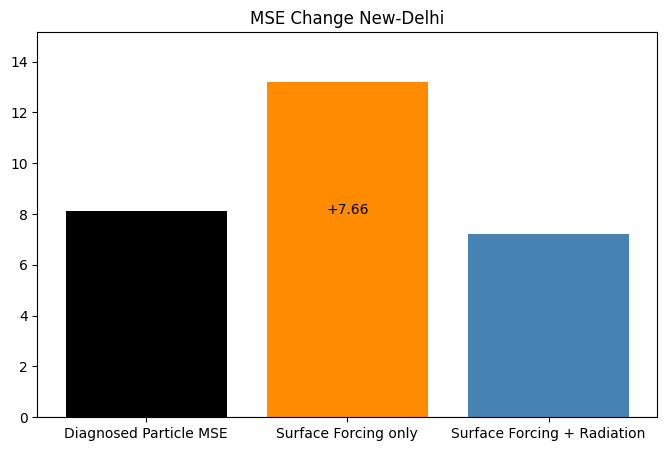

In [53]:
comparison = pd.Series({
    "Diagnosed Particle MSE": delta_mse,
    "Surface Forcing only": total_surface,
    "Surface Forcing + Radiation": predicted_change,
}) / 1000

fig, ax = plt.subplots(1, 1, figsize=(8,5))

bats = ax.bar(
    comparison.index,
    comparison.values,
    color= ["black", "darkorange", "steelblue"]
)

ax.axhline(0, color="gray", linewidth=0.8)
ax.set_label("Specific Energy Change [kJ/kg]")
ax.set_title("MSE Change New-Delhi")
ax.bar_label(bars, fmt="%+.2f", padding=4)
ax.margins(y=0.15)